# 7-Scenes Chess Hierarchical NeRF Colab Pipeline

This notebook runs the full pipeline in Google Colab with a stronger backbone:
- mounts Google Drive
- downloads the official 7-Scenes Chess dataset
- trains a wider hierarchical NeRF with coarse and fine sampling
- evaluates rendering quality
- estimates camera pose with RGB + depth
- runs conservative model refinement
- saves checkpoints, images, and outputs into one Google Drive folder


In [2]:
# Colab setup
%pip install -q pillow matplotlib imageio tqdm

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import math
import os
import random
import shutil
import zipfile
import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('NumPy version:', np.__version__)
print('PyTorch version:', torch.__version__)
print('Using device:', DEVICE)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NumPy version: 2.0.2
PyTorch version: 2.10.0+cu128
Using device: cuda


In [3]:
# Paths and dataset download
DRIVE_ROOT = Path('/content/drive/MyDrive')
PROJECT_DIR = DRIVE_ROOT / '7scenes_hierarchical_nerf_pipeline'
DATA_DIR = PROJECT_DIR / 'data'
OUTPUT_DIR = PROJECT_DIR / 'outputs'
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
VIS_DIR = OUTPUT_DIR / 'visualizations'
POSE_DIR = OUTPUT_DIR / 'pose_estimation'
REFINE_DIR = OUTPUT_DIR / 'refinement'
for d in [PROJECT_DIR, DATA_DIR, OUTPUT_DIR, CHECKPOINT_DIR, VIS_DIR, POSE_DIR, REFINE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CHESS_URL = 'https://download.microsoft.com/download/4/9/4/4945E6F5-16A1-4E28-BD35-82D6EAFB8A9B/chess.zip'
SCENE_DIR = DATA_DIR / 'chess'

print('Project dir:', PROJECT_DIR)
print('Scene dir:', SCENE_DIR)
print('Outputs dir:', OUTPUT_DIR)



Project dir: /content/drive/MyDrive/7scenes_hierarchical_nerf_pipeline
Scene dir: /content/drive/MyDrive/7scenes_hierarchical_nerf_pipeline/data/chess
Outputs dir: /content/drive/MyDrive/7scenes_hierarchical_nerf_pipeline/outputs


In [4]:
# Config
ORIG_W, ORIG_H = 640, 480
ORIG_FX, ORIG_FY, ORIG_CX, ORIG_CY = 585.0, 585.0, 320.0, 240.0

DOWNSAMPLE = 2
MAX_TRAIN_IMAGES = 192
MAX_TEST_IMAGES = 12
BATCH_RAYS = 4096
NUM_STEPS = 15000
LR = 2.0e-4
NEAR = 0.1
FAR = 4.5
NUM_COARSE_SAMPLES = 64
NUM_FINE_SAMPLES = 96
NUM_SAMPLES = NUM_COARSE_SAMPLES + NUM_FINE_SAMPLES
RGB_LOSS_WEIGHT = 1.0
DEPTH_LOSS_WEIGHT = 0.10
VAL_RENDER_INTERVAL = 3000
CHECKPOINT_EVERY = 500
VAL_FRAME_COUNT = 4
USE_OPENCV_CAMERA_CONVENTION = True
MODEL_HIDDEN = 320
MODEL_LAYERS = 10
POS_FREQS = 12
DIR_FREQS = 4
RENDER_CHUNK = 1024
USE_AMP = True
TRAIN_RESUME = True
REFINE_RESUME = True

POSE_ESTIMATION_ITERS = 1500
POSE_BATCH_RAYS = 1024
POSE_LR = 3e-3
POSE_RGB_LOSS_WEIGHT = 1.0
POSE_DEPTH_LOSS_WEIGHT = 0.20
INIT_ROT_PERTURB_DEG = 3.0
INIT_TRANS_PERTURB_M = torch.tensor([0.03, -0.02, 0.03], dtype=torch.float32, device=DEVICE)

REFINE_STEPS = 300
REFINE_BATCH_RAYS = 4096
REFINE_LR = 1e-5
REFINE_DEPTH_LOSS_WEIGHT = 0.30
REFINE_TRAIN_IMAGES = 48
REFINE_CHECKPOINT_EVERY = 100
REFINE_EVAL_EVERY = 100
POSE_FRAME_COUNT = 4
REFINE_FRAME_COUNT = 4

W, H = ORIG_W // DOWNSAMPLE, ORIG_H // DOWNSAMPLE
FX, FY, CX, CY = ORIG_FX / DOWNSAMPLE, ORIG_FY / DOWNSAMPLE, ORIG_CX / DOWNSAMPLE, ORIG_CY / DOWNSAMPLE

CONFIG = {
    'downsample': DOWNSAMPLE,
    'max_train_images': MAX_TRAIN_IMAGES,
    'max_test_images': MAX_TEST_IMAGES,
    'batch_rays': BATCH_RAYS,
    'num_steps': NUM_STEPS,
    'lr': LR,
    'near': NEAR,
    'far': FAR,
    'num_coarse_samples': NUM_COARSE_SAMPLES,
    'num_fine_samples': NUM_FINE_SAMPLES,
    'rgb_loss_weight': RGB_LOSS_WEIGHT,
    'depth_loss_weight': DEPTH_LOSS_WEIGHT,
    'checkpoint_every': CHECKPOINT_EVERY,
    'val_frame_count': VAL_FRAME_COUNT,
    'opencv_camera_convention': USE_OPENCV_CAMERA_CONVENTION,
    'model_hidden': MODEL_HIDDEN,
    'model_layers': MODEL_LAYERS,
    'pos_freqs': POS_FREQS,
    'dir_freqs': DIR_FREQS,
    'render_chunk': RENDER_CHUNK,
    'mixed_precision': USE_AMP,
    'train_resume': TRAIN_RESUME,
    'refine_resume': REFINE_RESUME,
    'refine_steps': REFINE_STEPS,
    'refine_lr': REFINE_LR,
    'refine_depth_loss_weight': REFINE_DEPTH_LOSS_WEIGHT,
    'refine_checkpoint_every': REFINE_CHECKPOINT_EVERY,
    'refine_eval_every': REFINE_EVAL_EVERY,
    'pose_frame_count': POSE_FRAME_COUNT,
    'refine_frame_count': REFINE_FRAME_COUNT,
}

for k, v in CONFIG.items():
    print(f'{k}: {v}')
print('AMP enabled for CUDA training:', USE_AMP and DEVICE.type == 'cuda')
print('Resume enabled for training:', TRAIN_RESUME)
print('Resume enabled for refinement:', REFINE_RESUME)
print('Hierarchical sampling enabled with coarse + fine fields.')
print('Stronger quality profile enabled for 15 GB class GPUs.')
print('Best checkpoint selection uses average PSNR over multiple test frames.')
print('Pose estimation and refinement summaries use multiple held-out frames.')



downsample: 2
max_train_images: 192
max_test_images: 12
batch_rays: 4096
num_steps: 15000
lr: 0.0002
near: 0.1
far: 4.5
num_coarse_samples: 64
num_fine_samples: 96
rgb_loss_weight: 1.0
depth_loss_weight: 0.1
checkpoint_every: 500
val_frame_count: 4
opencv_camera_convention: True
model_hidden: 320
model_layers: 10
pos_freqs: 12
dir_freqs: 4
render_chunk: 1024
mixed_precision: True
train_resume: True
refine_resume: True
refine_steps: 300
refine_lr: 1e-05
refine_depth_loss_weight: 0.3
refine_checkpoint_every: 100
refine_eval_every: 100
pose_frame_count: 4
refine_frame_count: 4
AMP enabled for CUDA training: True
Resume enabled for training: True
Resume enabled for refinement: True
Hierarchical sampling enabled with coarse + fine fields.
Stronger quality profile enabled for 15 GB class GPUs.
Best checkpoint selection uses average PSNR over multiple test frames.
Pose estimation and refinement summaries use multiple held-out frames.


In [5]:
# Data helpers
TRAIN_SPLIT = SCENE_DIR / 'TrainSplit.txt'
TEST_SPLIT = SCENE_DIR / 'TestSplit.txt'

def read_split_file(path):
    return [line.strip() for line in path.read_text().splitlines() if line.strip()]

def sequence_name_to_dir(name):
    return SCENE_DIR / f'seq-{int(name.replace("sequence", "")):02d}'

def load_pose(path):
    return np.loadtxt(path).astype(np.float32)

def load_rgb(path, downsample):
    img = Image.open(path).convert('RGB')
    if downsample > 1:
        img = img.resize((img.width // downsample, img.height // downsample), Image.Resampling.LANCZOS)
    return np.asarray(img).astype(np.float32) / 255.0

def load_depth(path, downsample):
    depth = Image.open(path)
    if downsample > 1:
        depth = depth.resize((depth.width // downsample, depth.height // downsample), Image.Resampling.NEAREST)
    arr = np.asarray(depth).astype(np.float32)
    valid = arr != 65535.0
    arr = arr / 1000.0
    arr[~valid] = 0.0
    return arr, valid.astype(np.float32)

def collect_frames(sequence_names, max_images=None):
    frames = []
    for seq_name in sequence_names:
        seq_dir = sequence_name_to_dir(seq_name)
        for color_path in sorted(seq_dir.glob('*.color.png')):
            stem = color_path.name.replace('.color.png', '')
            pose_path = seq_dir / f'{stem}.pose.txt'
            depth_path = seq_dir / f'{stem}.depth.png'
            if pose_path.exists() and depth_path.exists():
                frames.append({'sequence': seq_name, 'stem': stem, 'color_path': color_path, 'depth_path': depth_path, 'pose_path': pose_path})
    if max_images is not None and len(frames) > max_images:
        idx = np.linspace(0, len(frames) - 1, max_images, dtype=int)
        frames = [frames[i] for i in idx]
    return frames

def load_dataset(frame_records):
    images, depths, masks, poses = [], [], [], []
    for rec in tqdm(frame_records, desc='Loading dataset'):
        images.append(load_rgb(rec['color_path'], DOWNSAMPLE))
        d, m = load_depth(rec['depth_path'], DOWNSAMPLE)
        depths.append(d)
        masks.append(m)
        poses.append(load_pose(rec['pose_path']))
    return (
        torch.from_numpy(np.stack(images)).float().to(DEVICE),
        torch.from_numpy(np.stack(depths)).float().to(DEVICE),
        torch.from_numpy(np.stack(masks)).float().to(DEVICE),
        torch.from_numpy(np.stack(poses)).float().to(DEVICE),
    )

train_frames = collect_frames(read_split_file(TRAIN_SPLIT), MAX_TRAIN_IMAGES)
test_frames = collect_frames(read_split_file(TEST_SPLIT), MAX_TEST_IMAGES)
train_images, train_depths, train_masks, train_poses = load_dataset(train_frames)
test_images, test_depths, test_masks, test_poses = load_dataset(test_frames)
print('train_images:', tuple(train_images.shape))
print('test_images:', tuple(test_images.shape))


Loading dataset: 100%|██████████| 12/12 [00:13<00:00,  1.16s/it]

train_images: (192, 240, 320, 3)
test_images: (12, 240, 320, 3)


In [6]:
# NeRF and rendering
def get_ray_directions(h, w, fx, fy, cx, cy, device):
    ys, xs = torch.meshgrid(torch.arange(h, dtype=torch.float32, device=device), torch.arange(w, dtype=torch.float32, device=device), indexing='ij')
    if USE_OPENCV_CAMERA_CONVENTION:
        return torch.stack([(xs - cx) / fx, (ys - cy) / fy, torch.ones_like(xs)], dim=-1)
    return torch.stack([(xs - cx) / fx, -(ys - cy) / fy, -torch.ones_like(xs)], dim=-1)

def get_rays(directions, c2w):
    rot = c2w[:3, :3]
    trans = c2w[:3, 3]
    rays_d = directions @ rot.T
    rays_d = rays_d / torch.norm(rays_d, dim=-1, keepdim=True)
    rays_o = trans.expand_as(rays_d)
    return rays_o, rays_d

def positional_encoding(x, num_freqs):
    enc = [x]
    for i in range(num_freqs):
        f = 2.0 ** i
        enc.append(torch.sin(f * x))
        enc.append(torch.cos(f * x))
    return torch.cat(enc, dim=-1)

class RadianceField(nn.Module):
    def __init__(self, pos_freqs=10, dir_freqs=4, hidden=320, num_layers=10):
        super().__init__()
        self.pos_freqs = pos_freqs
        self.dir_freqs = dir_freqs
        self.hidden = hidden
        self.num_layers = num_layers
        in_xyz = 3 + 3 * 2 * pos_freqs
        in_dir = 3 + 3 * 2 * dir_freqs
        self.skip_layer = num_layers // 2
        self.layers = nn.ModuleList()
        for i in range(num_layers):
            if i == 0:
                inp = in_xyz
            elif i == self.skip_layer:
                inp = hidden + in_xyz
            else:
                inp = hidden
            self.layers.append(nn.Linear(inp, hidden))
        self.sigma_head = nn.Linear(hidden, 1)
        self.feature_head = nn.Linear(hidden, hidden)
        self.color_head = nn.Sequential(
            nn.Linear(hidden + in_dir, hidden // 2),
            nn.ReLU(True),
            nn.Linear(hidden // 2, 3),
            nn.Sigmoid(),
        )

    def forward(self, xyz, dirs):
        xyz_enc = positional_encoding(xyz, self.pos_freqs)
        dir_enc = positional_encoding(dirs, self.dir_freqs)
        h = xyz_enc
        for i, layer in enumerate(self.layers):
            if i == self.skip_layer:
                h = torch.cat([h, xyz_enc], dim=-1)
            h = F.relu(layer(h))
        sigma = F.relu(self.sigma_head(h))
        feat = self.feature_head(h)
        rgb = self.color_head(torch.cat([feat, dir_enc], dim=-1))
        return rgb, sigma

class HierarchicalNeRF(nn.Module):
    def __init__(self, pos_freqs=10, dir_freqs=4, hidden=320, num_layers=10):
        super().__init__()
        self.coarse = RadianceField(pos_freqs=pos_freqs, dir_freqs=dir_freqs, hidden=hidden, num_layers=num_layers)
        self.fine = RadianceField(pos_freqs=pos_freqs, dir_freqs=dir_freqs, hidden=hidden, num_layers=num_layers)


def volume_render(rgb, sigma, z_vals):
    deltas = z_vals[:, 1:] - z_vals[:, :-1]
    deltas = torch.cat([deltas, 1e10 * torch.ones_like(deltas[:, :1])], dim=-1)
    alpha = 1.0 - torch.exp(-sigma * deltas)
    trans = torch.cumprod(torch.cat([torch.ones((z_vals.shape[0], 1), device=z_vals.device), 1.0 - alpha + 1e-10], dim=-1), dim=-1)[:, :-1]
    weights = alpha * trans
    rgb_map = torch.sum(weights[..., None] * rgb, dim=1)
    depth_map = torch.sum(weights * z_vals, dim=1)
    acc_map = torch.sum(weights, dim=1)
    rgb_map = rgb_map + (1.0 - acc_map[..., None])
    return rgb_map, depth_map, acc_map, weights


def run_field(field, rays_o, rays_d, z_vals):
    pts = rays_o[:, None, :] + rays_d[:, None, :] * z_vals[..., None]
    view_dirs = rays_d[:, None, :].expand_as(pts)
    rgb, sigma = field(pts.reshape(-1, 3), view_dirs.reshape(-1, 3))
    rgb = rgb.reshape(z_vals.shape[0], z_vals.shape[1], 3)
    sigma = sigma.reshape(z_vals.shape[0], z_vals.shape[1])
    return volume_render(rgb, sigma, z_vals)


def sample_coarse_z_vals(rays_o, near, far, num_samples, perturb):
    t_vals = torch.linspace(0.0, 1.0, num_samples, device=rays_o.device)
    z_vals = (near * (1.0 - t_vals) + far * t_vals).expand(rays_o.shape[0], num_samples)
    if perturb:
        mids = 0.5 * (z_vals[:, :-1] + z_vals[:, 1:])
        lower = torch.cat([z_vals[:, :1], mids], dim=-1)
        upper = torch.cat([mids, z_vals[:, -1:]], dim=-1)
        z_vals = lower + (upper - lower) * torch.rand_like(z_vals)
    return z_vals


def sample_pdf(bins, weights, num_samples, deterministic=False):
    weights = weights + 1e-5
    pdf = weights / torch.sum(weights, dim=-1, keepdim=True)
    cdf = torch.cumsum(pdf, dim=-1)
    cdf = torch.cat([torch.zeros_like(cdf[:, :1]), cdf], dim=-1)
    if deterministic:
        # Avoid including exactly 1.0, which can push searchsorted past the last valid bin.
        u = torch.linspace(0.5 / num_samples, 1.0 - 0.5 / num_samples, num_samples, device=bins.device)
        u = u.expand(cdf.shape[0], num_samples)
    else:
        u = torch.rand(cdf.shape[0], num_samples, device=bins.device)
    inds = torch.searchsorted(cdf, u, right=True)
    below = torch.clamp(inds - 1, min=0, max=bins.shape[-1] - 1)
    above = torch.clamp(inds, min=1, max=bins.shape[-1] - 1)
    cdf_below = torch.gather(cdf, 1, below)
    cdf_above = torch.gather(cdf, 1, above)
    bins_below = torch.gather(bins, 1, below)
    bins_above = torch.gather(bins, 1, above)
    denom = torch.where((cdf_above - cdf_below) < 1e-5, torch.ones_like(cdf_above), cdf_above - cdf_below)
    t = (u - cdf_below) / denom
    return bins_below + t * (bins_above - bins_below)


def render_rays(model, rays_o, rays_d, near, far, num_samples, perturb=True):
    coarse_samples = min(NUM_COARSE_SAMPLES, num_samples)
    fine_samples = max(num_samples - coarse_samples, 0)
    z_coarse = sample_coarse_z_vals(rays_o, near, far, coarse_samples, perturb)
    coarse_rgb, coarse_depth, coarse_acc, coarse_weights = run_field(model.coarse, rays_o, rays_d, z_coarse)

    if fine_samples <= 0:
        return coarse_rgb, coarse_depth, coarse_acc

    z_mids = 0.5 * (z_coarse[:, :-1] + z_coarse[:, 1:])
    z_fine = sample_pdf(z_mids, coarse_weights[:, 1:-1].detach(), fine_samples, deterministic=not perturb)
    z_all = torch.sort(torch.cat([z_coarse, z_fine], dim=-1), dim=-1).values
    fine_rgb, fine_depth, fine_acc, _ = run_field(model.fine, rays_o, rays_d, z_all)
    return fine_rgb, fine_depth, fine_acc

@torch.no_grad()
def render_image(model, c2w, chunk=RENDER_CHUNK):
    rays_o, rays_d = get_rays(ray_dirs_cam, c2w)
    rays_o = rays_o.reshape(-1, 3)
    rays_d = rays_d.reshape(-1, 3)
    rgb_chunks, depth_chunks = [], []
    for start in range(0, rays_o.shape[0], chunk):
        end = start + chunk
        rgb, depth, _ = render_rays(model, rays_o[start:end], rays_d[start:end], NEAR, FAR, NUM_SAMPLES, perturb=False)
        rgb_chunks.append(rgb)
        depth_chunks.append(depth)
    return torch.cat(rgb_chunks, 0).reshape(H, W, 3).clamp(0.0, 1.0), torch.cat(depth_chunks, 0).reshape(H, W)

ray_dirs_cam = get_ray_directions(H, W, FX, FY, CX, CY, DEVICE)
model = HierarchicalNeRF(pos_freqs=POS_FREQS, dir_freqs=DIR_FREQS, hidden=MODEL_HIDDEN, num_layers=MODEL_LAYERS).to(DEVICE)
baseline_model = HierarchicalNeRF(pos_freqs=POS_FREQS, dir_freqs=DIR_FREQS, hidden=MODEL_HIDDEN, num_layers=MODEL_LAYERS).to(DEVICE)
print('Hierarchical coarse+fine models initialized.')




Hierarchical coarse+fine models initialized.


In [7]:
# Training
@torch.no_grad()
def build_ray_pool(images, depths, masks, poses):
    rays_o_all, rays_d_all, rgb_all, depth_all, mask_all = [], [], [], [], []
    for img, depth, mask, pose in tqdm(list(zip(images, depths, masks, poses)), desc='Building ray pool'):
        rays_o, rays_d = get_rays(ray_dirs_cam, pose)
        rays_o_all.append(rays_o.reshape(-1, 3))
        rays_d_all.append(rays_d.reshape(-1, 3))
        rgb_all.append(img.reshape(-1, 3))
        depth_all.append(depth.reshape(-1))
        mask_all.append(mask.reshape(-1))
    return torch.cat(rays_o_all, 0), torch.cat(rays_d_all, 0), torch.cat(rgb_all, 0), torch.cat(depth_all, 0), torch.cat(mask_all, 0)

@torch.no_grad()
def evaluate_model(model, frame_indices):
    metrics = []
    rendered = []
    model.eval()
    for idx in frame_indices:
        pred_rgb, pred_depth = render_image(model, test_poses[idx])
        gt_rgb = test_images[idx]
        gt_depth = test_depths[idx]
        gt_mask = test_masks[idx] > 0.5
        psnr = -10.0 * math.log10(F.mse_loss(pred_rgb, gt_rgb).item())
        depth_mae = (pred_depth[gt_mask] - gt_depth[gt_mask]).abs().mean().item() if gt_mask.any() else float('nan')
        metrics.append({'index': idx, 'psnr': psnr, 'depth_mae': depth_mae})
        rendered.append((idx, gt_rgb, pred_rgb, pred_depth))
    avg_psnr = sum(m['psnr'] for m in metrics) / len(metrics)
    valid_depth_mae = [m['depth_mae'] for m in metrics if not math.isnan(m['depth_mae'])]
    avg_depth_mae = sum(valid_depth_mae) / len(valid_depth_mae) if valid_depth_mae else float('nan')
    return metrics, rendered, avg_psnr, avg_depth_mae


def get_config_signature(config):
    keys = [
        'downsample', 'max_train_images', 'batch_rays', 'num_steps', 'lr', 'near', 'far',
        'num_coarse_samples', 'num_fine_samples', 'rgb_loss_weight', 'depth_loss_weight',
        'model_hidden', 'model_layers', 'pos_freqs', 'dir_freqs', 'render_chunk', 'val_frame_count'
    ]
    return {k: config[k] for k in keys}


train_rays_o, train_rays_d, train_rgb_pool, train_depth_pool, train_mask_pool = build_ray_pool(train_images, train_depths, train_masks, train_poses)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_STEPS, eta_min=LR * 0.2)
scaler = GradScaler(DEVICE.type, enabled=(USE_AMP and DEVICE.type == 'cuda'))
loss_history = []
val_dir = VIS_DIR / 'train_validation'
val_dir.mkdir(exist_ok=True)
resume_path = CHECKPOINT_DIR / 'hierarchical_nerf_resume_latest.pth'
best_path = CHECKPOINT_DIR / 'hierarchical_nerf_best.pth'
start_step = 0
val_frame_indices = list(range(min(VAL_FRAME_COUNT, len(test_images))))
current_signature = get_config_signature(CONFIG)
best_val_psnr = float('-inf')
best_val_step = -1
best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
resumed = False

if TRAIN_RESUME and resume_path.exists():
    resume_state = torch.load(resume_path, map_location=DEVICE)
    saved_signature = resume_state.get('config_signature')
    if saved_signature is None and 'config' in resume_state:
        saved_signature = get_config_signature(resume_state['config'])
    if saved_signature == current_signature:
        model.load_state_dict(resume_state['model_state_dict'])
        optimizer.load_state_dict(resume_state['optimizer_state_dict'])
        scheduler.load_state_dict(resume_state['scheduler_state_dict'])
        if 'scaler_state_dict' in resume_state and resume_state['scaler_state_dict']:
            scaler.load_state_dict(resume_state['scaler_state_dict'])
        loss_history = list(resume_state.get('loss_history', []))
        start_step = int(resume_state.get('step', -1)) + 1
        resumed = True
        print(f'Resumed training from step {start_step} using {resume_path}')
    else:
        print('Resume checkpoint config mismatch detected. Ignoring stale resume state and starting fresh.')
else:
    print('Starting fresh HierarchicalNeRF training run.')

# Always bootstrap the best checkpoint from the currently loaded model, not stale metadata.
bootstrap_metrics, _, bootstrap_avg_psnr, bootstrap_avg_depth_mae = evaluate_model(model, val_frame_indices)
best_val_psnr = bootstrap_avg_psnr
best_val_step = start_step - 1 if resumed else -1
best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
torch.save({
    'step': best_val_step,
    'best_val_psnr': best_val_psnr,
    'best_val_step': best_val_step,
    'model_state_dict': model.state_dict(),
    'config': CONFIG,
    'config_signature': current_signature,
    'val_metrics': bootstrap_metrics,
}, best_path)
print(f'Bootstrapped best checkpoint from current model with avg PSNR={best_val_psnr:.2f} dB and avg depth MAE={bootstrap_avg_depth_mae:.3f} m')

model.train()
for step in tqdm(range(start_step, NUM_STEPS), desc='Training HierarchicalNeRF'):
    idx = torch.randint(0, train_rays_o.shape[0], (BATCH_RAYS,), device=DEVICE)
    rays_o = train_rays_o[idx]
    rays_d = train_rays_d[idx]
    rgb_gt = train_rgb_pool[idx]
    depth_gt = train_depth_pool[idx]
    depth_mask = train_mask_pool[idx] > 0.5
    optimizer.zero_grad(set_to_none=True)
    with autocast(device_type=DEVICE.type, enabled=(USE_AMP and DEVICE.type == 'cuda')):
        rgb_pred, depth_pred, _ = render_rays(model, rays_o, rays_d, NEAR, FAR, NUM_SAMPLES, perturb=True)
        rgb_loss = F.mse_loss(rgb_pred, rgb_gt)
        depth_loss = F.smooth_l1_loss(depth_pred[depth_mask], depth_gt[depth_mask]) if depth_mask.any() else torch.zeros((), device=DEVICE)
        loss = RGB_LOSS_WEIGHT * rgb_loss + DEPTH_LOSS_WEIGHT * depth_loss
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    scaler.step(optimizer)
    scaler.update()
    loss_history.append(loss.item())
    scheduler.step()

    should_checkpoint = ((step + 1) % CHECKPOINT_EVERY == 0) or ((step + 1) == NUM_STEPS)
    should_validate = ((step + 1) % VAL_RENDER_INTERVAL == 0) or (step == NUM_STEPS - 1)

    if should_validate:
        metrics, rendered, avg_psnr, avg_depth_mae = evaluate_model(model, val_frame_indices)
        fig, axes = plt.subplots(len(rendered), 3, figsize=(16, 4 * len(rendered)))
        if len(rendered) == 1:
            axes = axes[None, :]
        for row, (frame_idx, gt_img, pred_img, pred_depth) in enumerate(rendered):
            frame_metrics = metrics[row]
            axes[row, 0].imshow(gt_img.detach().cpu().numpy())
            axes[row, 0].set_title(f'Ground Truth RGB #{frame_idx}')
            axes[row, 1].imshow(pred_img.detach().cpu().numpy())
            axes[row, 1].set_title(f"Rendered RGB #{frame_idx}\nPSNR={frame_metrics['psnr']:.2f} dB")
            axes[row, 2].imshow(pred_depth.detach().cpu().numpy(), cmap='magma')
            axes[row, 2].set_title(f"Rendered Depth #{frame_idx}\nMAE={frame_metrics['depth_mae']:.3f} m")
            [ax.axis('off') for ax in axes[row]]
        fig.suptitle(f'Validation Avg PSNR={avg_psnr:.2f} dB | Avg Depth MAE={avg_depth_mae:.3f} m', fontsize=14)
        plt.tight_layout()
        out_path = val_dir / f'hierarchical_nerf_val_{step+1:05d}.png'
        plt.savefig(out_path, dpi=140, bbox_inches='tight')
        plt.close(fig)
        if avg_psnr > best_val_psnr:
            best_val_psnr = avg_psnr
            best_val_step = step
            best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save({
                'step': step,
                'best_val_psnr': best_val_psnr,
                'best_val_step': best_val_step,
                'model_state_dict': model.state_dict(),
                'config': CONFIG,
                'config_signature': current_signature,
                'val_metrics': metrics,
            }, best_path)
            print(f'New best training checkpoint at step {step + 1} with avg PSNR={best_val_psnr:.2f} dB')
        model.train()

    if should_checkpoint:
        torch.save({
            'step': step,
            'model_state_dict': model.state_dict(),
            'best_model_state_dict': best_state_dict,
            'best_val_psnr': best_val_psnr,
            'best_val_step': best_val_step,
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'scaler_state_dict': scaler.state_dict(),
            'loss_history': loss_history,
            'config': CONFIG,
            'config_signature': current_signature,
        }, resume_path)

model.load_state_dict(best_state_dict)
checkpoint_path = CHECKPOINT_DIR / 'hierarchical_nerf_trained.pth'
torch.save({
    'step': best_val_step if best_val_step >= 0 else NUM_STEPS - 1,
    'best_val_psnr': best_val_psnr,
    'best_val_step': best_val_step,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),
    'scaler_state_dict': scaler.state_dict(),
    'loss_history': loss_history,
    'config': CONFIG,
    'config_signature': current_signature,
}, checkpoint_path)
baseline_model.load_state_dict(model.state_dict())
baseline_model.eval()
print('Saved trained checkpoint to:', checkpoint_path)
print('Saved best training checkpoint to:', best_path)
print('Saved resumable training state to:', resume_path)
print('Best validation step:', best_val_step + 1 if best_val_step >= 0 else 'bootstrapped current model used')



Building ray pool: 100%|██████████| 192/192 [00:00<00:00, 970.82it/s]


Resume checkpoint config mismatch detected. Ignoring stale resume state and starting fresh.


/tmp/ipykernel_2234/352221928.py:116: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at /pytorch/aten/src/ATen/native/BucketizationUtils.h:32.)
  inds = torch.searchsorted(cdf, u, right=True)


Bootstrapped best checkpoint from current model with avg PSNR=13.61 dB and avg depth MAE=2.356 m


Training HierarchicalNeRF:  20%|██        | 3000/15000 [34:58<85:11:24, 25.56s/it]

New best training checkpoint at step 3000 with avg PSNR=17.51 dB


Training HierarchicalNeRF:  40%|████      | 6000/15000 [1:09:48<64:23:48, 25.76s/it]

New best training checkpoint at step 6000 with avg PSNR=17.54 dB


Training HierarchicalNeRF: 100%|██████████| 15000/15000 [2:55:20<00:00,  1.43it/s]


Saved trained checkpoint to: /content/drive/MyDrive/7scenes_hierarchical_nerf_pipeline/outputs/checkpoints/hierarchical_nerf_trained.pth
Saved best training checkpoint to: /content/drive/MyDrive/7scenes_hierarchical_nerf_pipeline/outputs/checkpoints/hierarchical_nerf_best.pth
Saved resumable training state to: /content/drive/MyDrive/7scenes_hierarchical_nerf_pipeline/outputs/checkpoints/hierarchical_nerf_resume_latest.pth
Best validation step: 6000


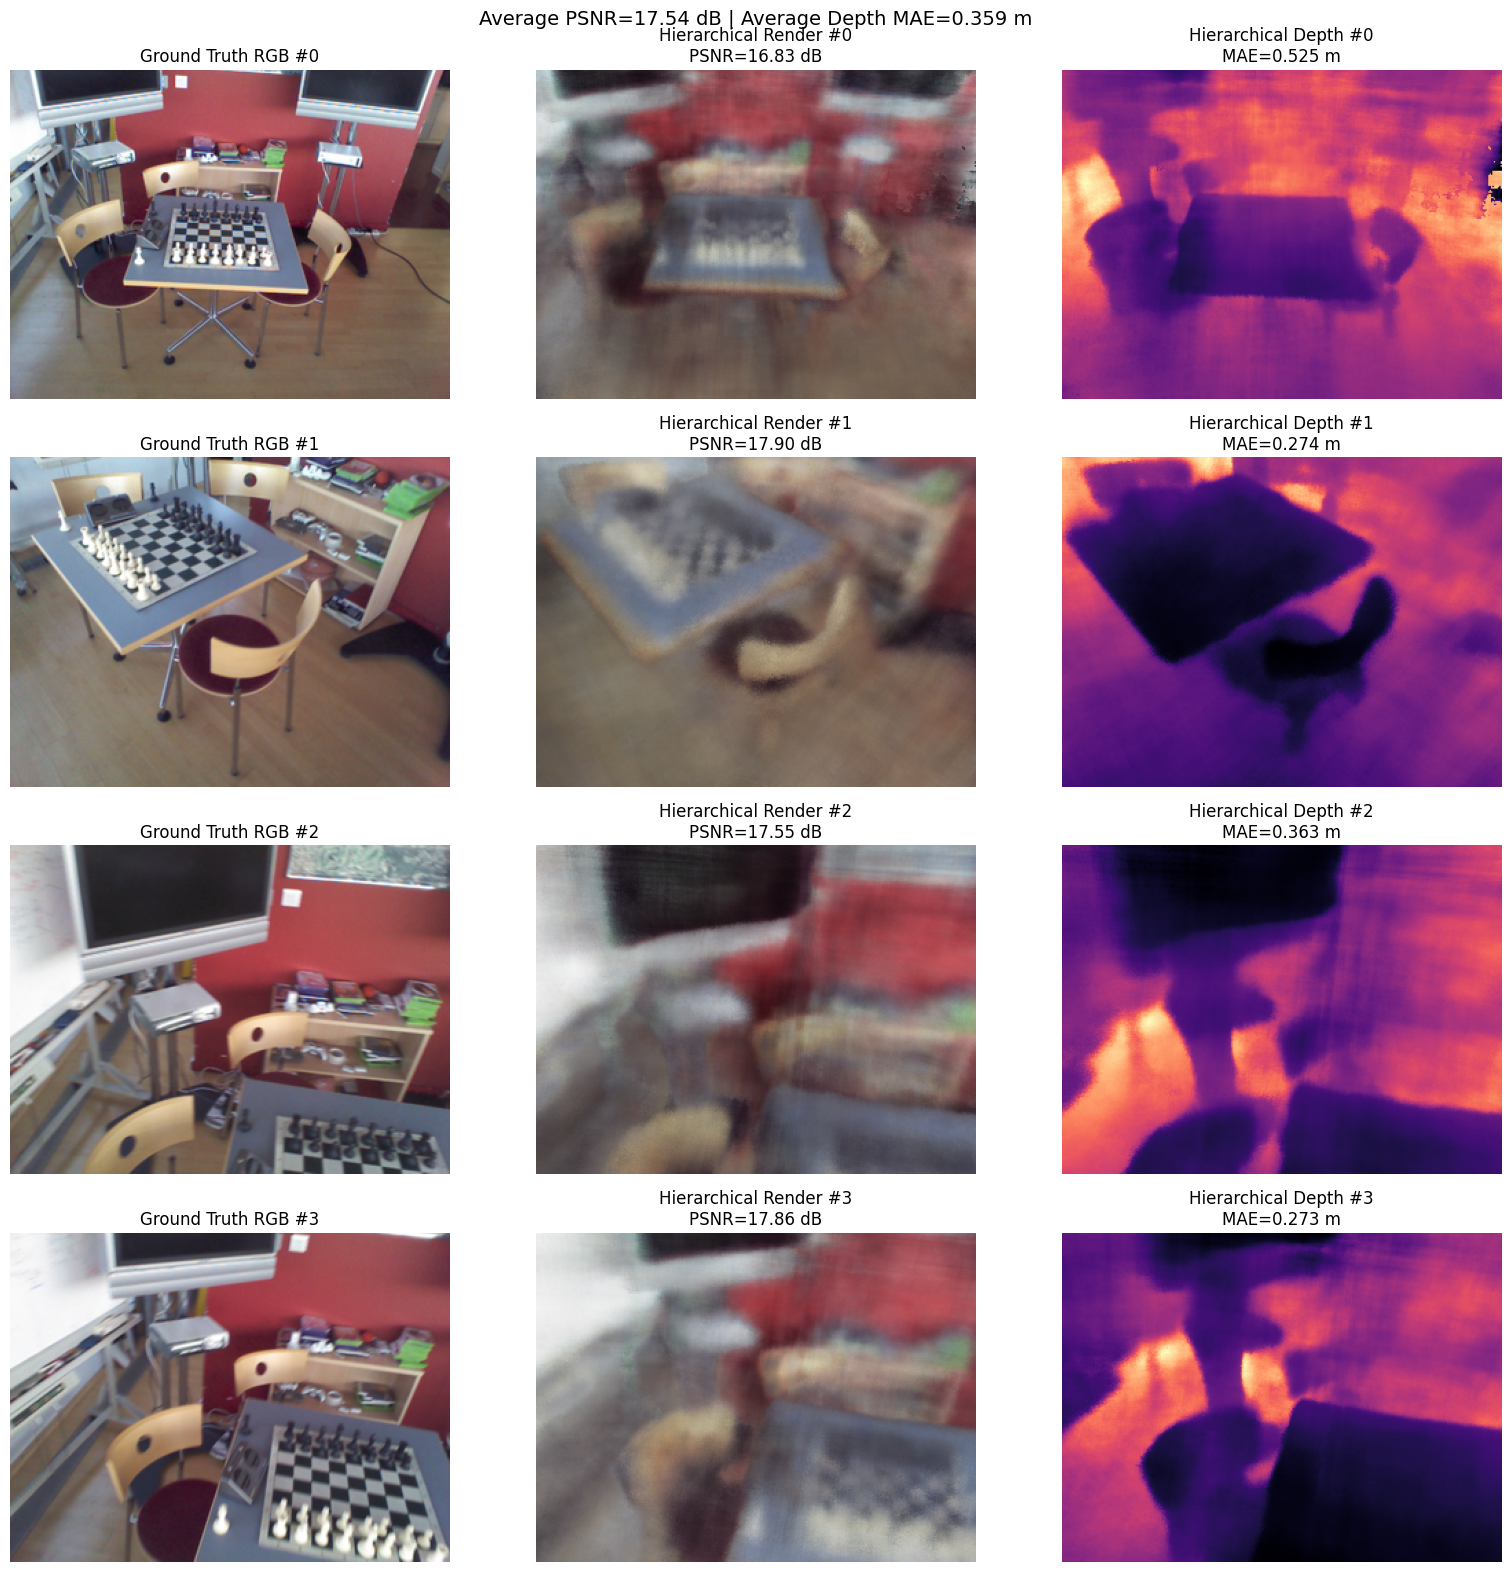

frame=0 psnr=16.83 dB depth_mae=0.525 m
frame=1 psnr=17.90 dB depth_mae=0.274 m
frame=2 psnr=17.55 dB depth_mae=0.363 m
frame=3 psnr=17.86 dB depth_mae=0.273 m
Saved evaluation image to: /content/drive/MyDrive/7scenes_hierarchical_nerf_pipeline/outputs/visualizations/checkpoint_eval_multiview.png
Average PSNR over 4 frames: 17.54 dB
Average depth MAE over 4 frames: 0.359 m


In [8]:
# Evaluation
model.eval()
eval_frame_indices = list(range(min(VAL_FRAME_COUNT, len(test_images))))
metrics, rendered, avg_psnr, avg_depth_mae = evaluate_model(model, eval_frame_indices)
fig, axes = plt.subplots(len(rendered), 3, figsize=(16, 4 * len(rendered)))
if len(rendered) == 1:
    axes = axes[None, :]
for row, (frame_idx, gt_rgb, pred_rgb, pred_depth) in enumerate(rendered):
    frame_metrics = metrics[row]
    axes[row, 0].imshow(gt_rgb.detach().cpu().numpy())
    axes[row, 0].set_title(f'Ground Truth RGB #{frame_idx}')
    axes[row, 1].imshow(pred_rgb.detach().cpu().numpy())
    axes[row, 1].set_title(f"Hierarchical Render #{frame_idx}\nPSNR={frame_metrics['psnr']:.2f} dB")
    axes[row, 2].imshow(pred_depth.detach().cpu().numpy(), cmap='magma')
    axes[row, 2].set_title(f"Hierarchical Depth #{frame_idx}\nMAE={frame_metrics['depth_mae']:.3f} m")
    [ax.axis('off') for ax in axes[row]]
fig.suptitle(f'Average PSNR={avg_psnr:.2f} dB | Average Depth MAE={avg_depth_mae:.3f} m', fontsize=14)
plt.tight_layout()
eval_vis = VIS_DIR / 'checkpoint_eval_multiview.png'
plt.savefig(eval_vis, dpi=140, bbox_inches='tight')
plt.show()
for metric in metrics:
    print(f"frame={metric['index']} psnr={metric['psnr']:.2f} dB depth_mae={metric['depth_mae']:.3f} m")
print('Saved evaluation image to:', eval_vis)
print(f'Average PSNR over {len(metrics)} frames: {avg_psnr:.2f} dB')
print(f'Average depth MAE over {len(metrics)} frames: {avg_depth_mae:.3f} m')


In [9]:
# Pose estimation helpers
def skew(v):
    x, y, z = v[0], v[1], v[2]
    return torch.stack([torch.stack([torch.zeros_like(x), -z, y]), torch.stack([z, torch.zeros_like(x), -x]), torch.stack([-y, x, torch.zeros_like(x)])])

def axis_angle_to_matrix(rotvec):
    theta = torch.linalg.norm(rotvec) + 1e-9
    k = rotvec / theta
    K = skew(k)
    I = torch.eye(3, device=rotvec.device, dtype=rotvec.dtype)
    return I + torch.sin(theta) * K + (1.0 - torch.cos(theta)) * (K @ K)

def compose_pose_delta(base_pose, rotvec, transvec):
    delta = torch.eye(4, device=base_pose.device, dtype=base_pose.dtype)
    delta[:3, :3] = axis_angle_to_matrix(rotvec)
    delta[:3, 3] = transvec
    return base_pose @ delta

def rotation_error_deg(est_pose, gt_pose):
    r_rel = est_pose[:3, :3] @ gt_pose[:3, :3].T
    trace = torch.clamp((torch.trace(r_rel) - 1.0) * 0.5, -1.0, 1.0)
    return torch.rad2deg(torch.arccos(trace)).item()

def translation_error_m(est_pose, gt_pose):
    return torch.linalg.norm(est_pose[:3, 3] - gt_pose[:3, 3]).item()

def estimate_pose_for_index(eval_idx=0):
    target_rgb = test_images[eval_idx]
    target_depth = test_depths[eval_idx]
    target_mask = test_masks[eval_idx]
    gt_pose = test_poses[eval_idx]
    init_pose = compose_pose_delta(gt_pose, torch.tensor([0.0, math.radians(INIT_ROT_PERTURB_DEG), 0.0], device=DEVICE), INIT_TRANS_PERTURB_M)
    rot_delta = nn.Parameter(torch.zeros(3, device=DEVICE))
    trans_delta = nn.Parameter(torch.zeros(3, device=DEVICE))
    optimizer = torch.optim.Adam([rot_delta, trans_delta], lr=POSE_LR)
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    for p in model.parameters():
        p.requires_grad_(False)
    model.eval()
    loss_history = []
    for _ in tqdm(range(POSE_ESTIMATION_ITERS), desc='Pose estimation'):
        pose = compose_pose_delta(init_pose, rot_delta, trans_delta)
        ys = torch.randint(0, H, (POSE_BATCH_RAYS,), device=DEVICE)
        xs = torch.randint(0, W, (POSE_BATCH_RAYS,), device=DEVICE)
        dirs = ray_dirs_cam[ys, xs]
        rays_o, rays_d = get_rays(dirs, pose)
        rgb_gt = target_rgb[ys, xs]
        depth_gt = target_depth[ys, xs]
        mask = target_mask[ys, xs] > 0.5
        optimizer.zero_grad(set_to_none=True)
        with autocast(device_type=DEVICE.type, enabled=(USE_AMP and DEVICE.type == 'cuda')):
            rgb_pred, depth_pred, _ = render_rays(model, rays_o, rays_d, NEAR, FAR, NUM_SAMPLES, perturb=False)
            rgb_loss = F.mse_loss(rgb_pred, rgb_gt)
            depth_loss = F.smooth_l1_loss(depth_pred[mask], depth_gt[mask]) if mask.any() else torch.zeros((), device=DEVICE)
            loss = POSE_RGB_LOSS_WEIGHT * rgb_loss + POSE_DEPTH_LOSS_WEIGHT * depth_loss
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())
    return init_pose.detach(), compose_pose_delta(init_pose, rot_delta, trans_delta).detach(), gt_pose.detach(), loss_history


Pose estimation: 100%|██████████| 1500/1500 [03:22<00:00,  7.39it/s]


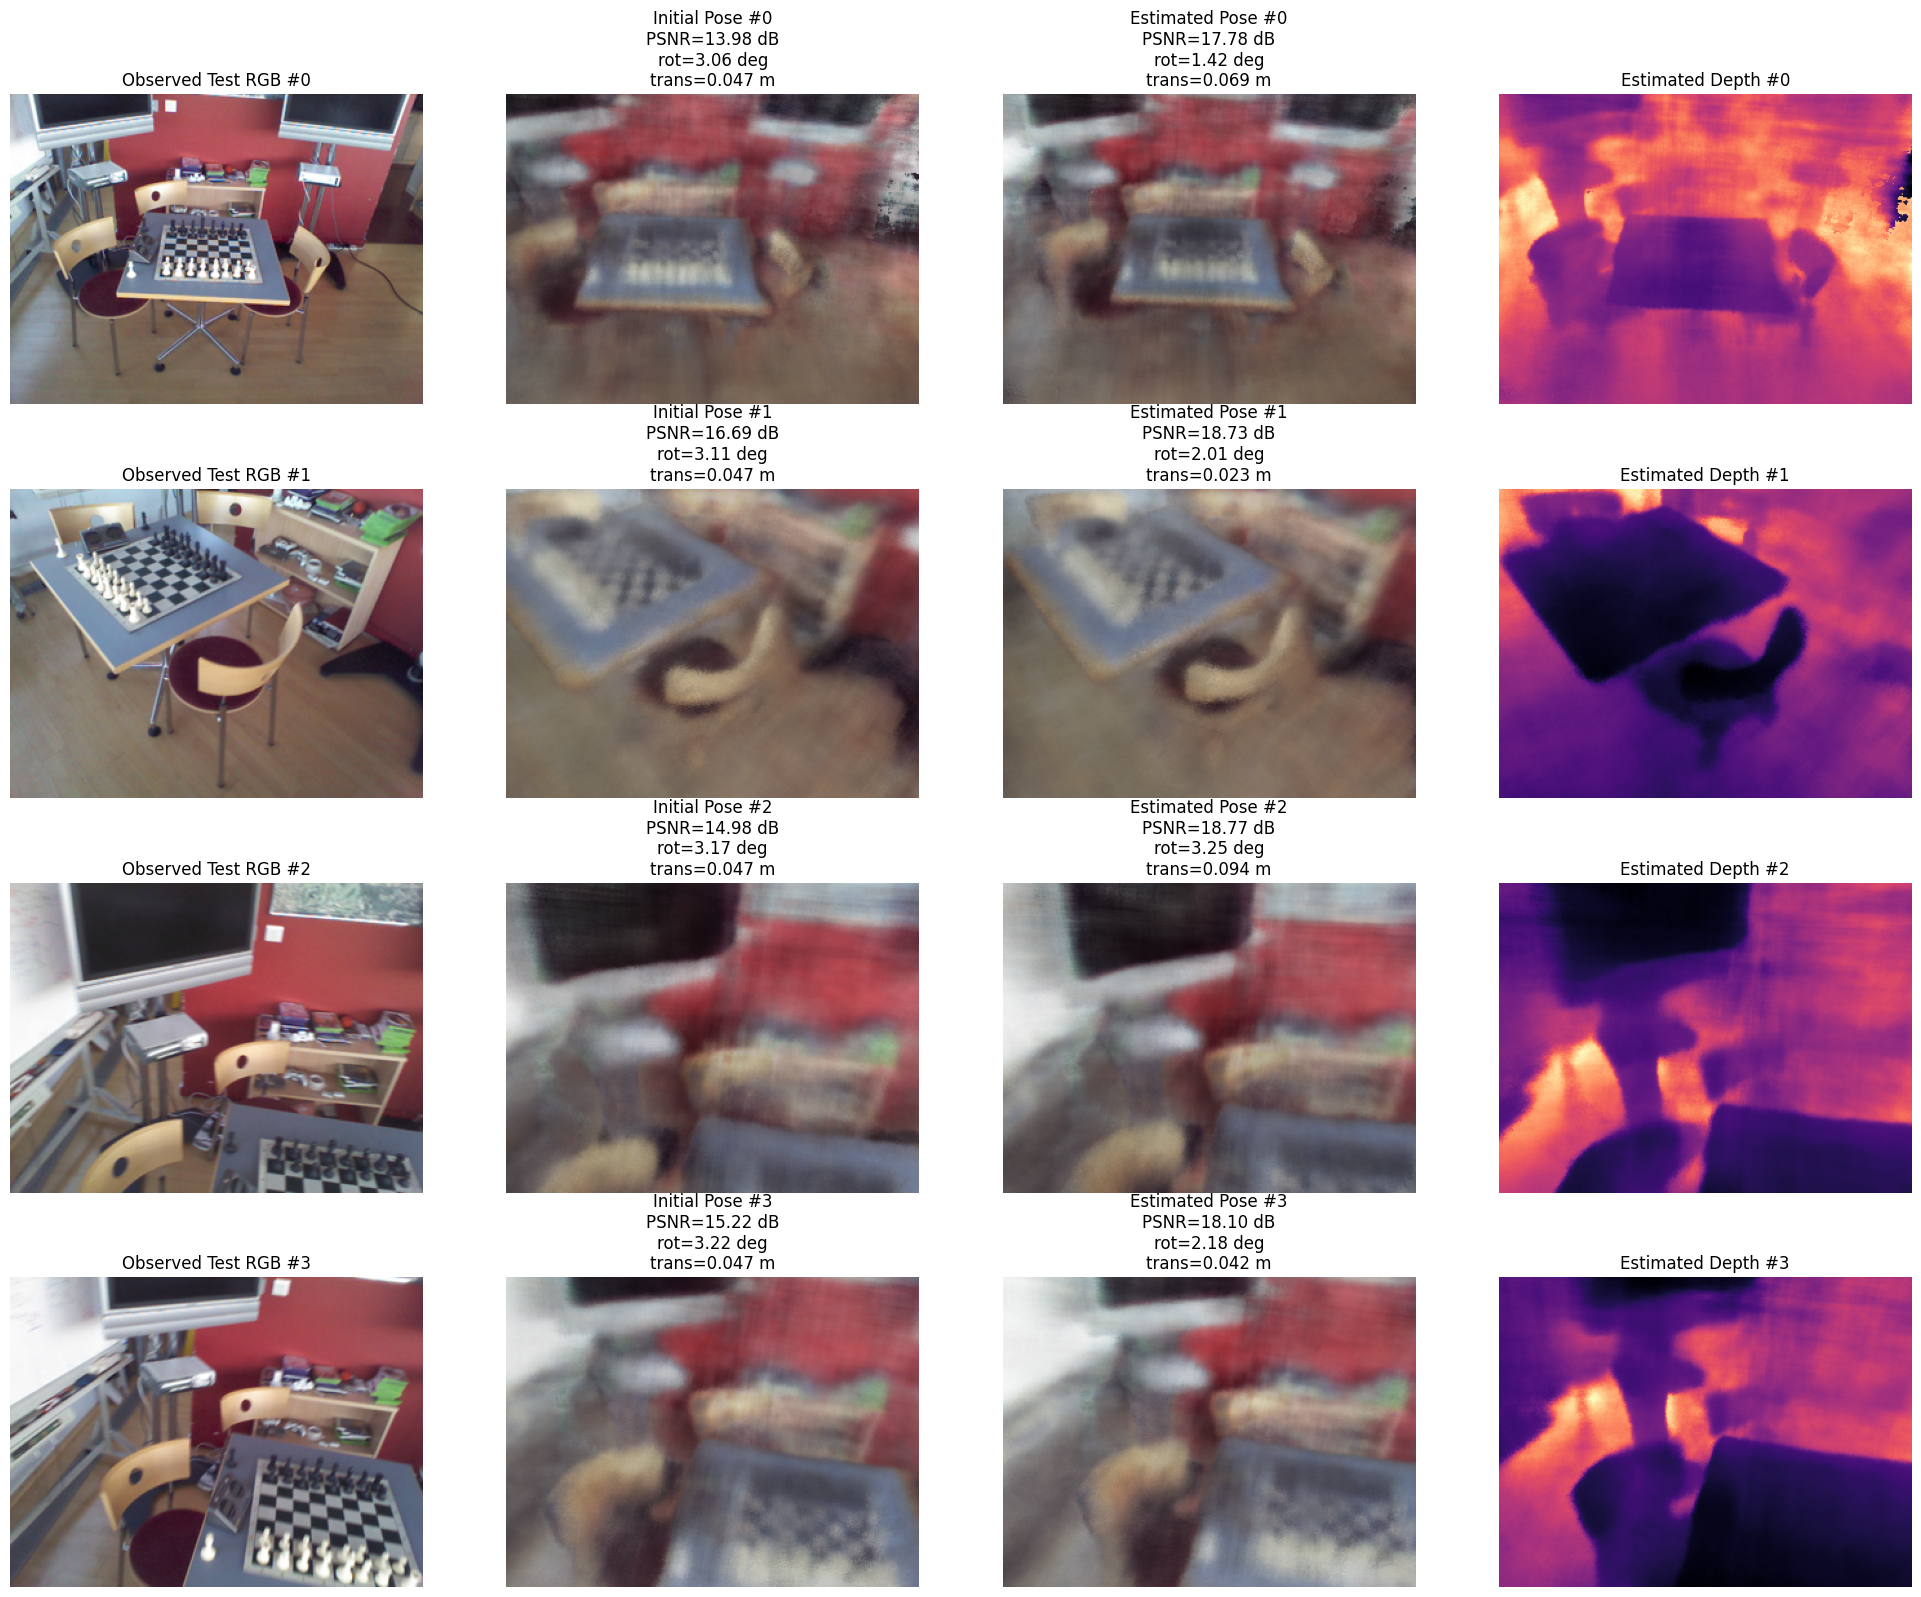

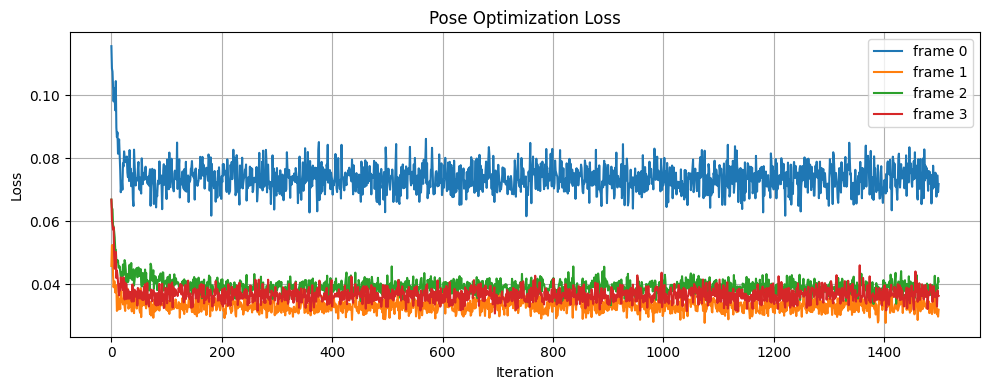

frame=0 init_psnr=13.98 est_psnr=17.78 init_rot=3.06 est_rot=1.42 init_trans=0.047 est_trans=0.069
frame=1 init_psnr=16.69 est_psnr=18.73 init_rot=3.11 est_rot=2.01 init_trans=0.047 est_trans=0.023
frame=2 init_psnr=14.98 est_psnr=18.77 init_rot=3.17 est_rot=3.25 init_trans=0.047 est_trans=0.094
frame=3 init_psnr=15.22 est_psnr=18.10 init_rot=3.22 est_rot=2.18 init_trans=0.047 est_trans=0.042
Saved pose estimation outputs to: /content/drive/MyDrive/7scenes_hierarchical_nerf_pipeline/outputs/pose_estimation
Average estimated-pose PSNR over 4 frames: 18.35 dB
Average estimated-pose rotation error: 2.22 deg
Average estimated-pose translation error: 0.057 m


In [10]:
# Pose estimation run
pose_eval_indices = list(range(min(POSE_FRAME_COUNT, len(test_images))))
pose_summaries = []
for eval_idx in pose_eval_indices:
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    init_pose, est_pose, gt_pose, pose_loss_history = estimate_pose_for_index(eval_idx)
    with torch.no_grad():
        init_render, _ = render_image(model, init_pose)
        est_render, est_depth = render_image(model, est_pose)
    target_rgb = test_images[eval_idx]
    target_depth = test_depths[eval_idx]
    target_mask = test_masks[eval_idx]
    init_rot_err = rotation_error_deg(init_pose, gt_pose)
    init_trans_err = translation_error_m(init_pose, gt_pose)
    est_rot_err = rotation_error_deg(est_pose, gt_pose)
    est_trans_err = translation_error_m(est_pose, gt_pose)
    init_psnr = -10.0 * math.log10(F.mse_loss(init_render, target_rgb).item())
    est_psnr = -10.0 * math.log10(F.mse_loss(est_render, target_rgb).item())
    pose_summaries.append({
        'index': eval_idx,
        'init_pose': init_pose,
        'est_pose': est_pose,
        'gt_pose': gt_pose,
        'loss_history': pose_loss_history,
        'init_render': init_render,
        'est_render': est_render,
        'est_depth': est_depth,
        'target_rgb': target_rgb,
        'target_depth': target_depth,
        'target_mask': target_mask,
        'init_rot_err': init_rot_err,
        'init_trans_err': init_trans_err,
        'est_rot_err': est_rot_err,
        'est_trans_err': est_trans_err,
        'init_psnr': init_psnr,
        'est_psnr': est_psnr,
    })

fig, axes = plt.subplots(len(pose_summaries), 4, figsize=(20, 4 * len(pose_summaries)))
if len(pose_summaries) == 1:
    axes = axes[None, :]
for row, summary in enumerate(pose_summaries):
    axes[row, 0].imshow(summary['target_rgb'].detach().cpu().numpy())
    axes[row, 0].set_title(f"Observed Test RGB #{summary['index']}")
    axes[row, 1].imshow(summary['init_render'].detach().cpu().numpy())
    axes[row, 1].set_title(f"Initial Pose #{summary['index']}\nPSNR={summary['init_psnr']:.2f} dB\nrot={summary['init_rot_err']:.2f} deg\ntrans={summary['init_trans_err']:.3f} m")
    axes[row, 2].imshow(summary['est_render'].detach().cpu().numpy())
    axes[row, 2].set_title(f"Estimated Pose #{summary['index']}\nPSNR={summary['est_psnr']:.2f} dB\nrot={summary['est_rot_err']:.2f} deg\ntrans={summary['est_trans_err']:.3f} m")
    axes[row, 3].imshow(summary['est_depth'].detach().cpu().numpy(), cmap='magma')
    axes[row, 3].set_title(f"Estimated Depth #{summary['index']}")
    [ax.axis('off') for ax in axes[row]]
plt.tight_layout()
pose_vis = POSE_DIR / 'hierarchical_nerf_pose_estimation_multiview.png'
plt.savefig(pose_vis, dpi=140, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 4))
for summary in pose_summaries:
    plt.plot(summary['loss_history'], label=f"frame {summary['index']}")
plt.title('Pose Optimization Loss')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.tight_layout()
loss_vis = POSE_DIR / 'pose_optimization_loss_multiview.png'
plt.savefig(loss_vis, dpi=140, bbox_inches='tight')
plt.show()

for summary in pose_summaries:
    idx = summary['index']
    np.savetxt(POSE_DIR / f'gt_pose_{idx:02d}.txt', summary['gt_pose'].detach().cpu().numpy(), fmt='%.8f')
    np.savetxt(POSE_DIR / f'estimated_pose_{idx:02d}.txt', summary['est_pose'].detach().cpu().numpy(), fmt='%.8f')
    print(f"frame={idx} init_psnr={summary['init_psnr']:.2f} est_psnr={summary['est_psnr']:.2f} init_rot={summary['init_rot_err']:.2f} est_rot={summary['est_rot_err']:.2f} init_trans={summary['init_trans_err']:.3f} est_trans={summary['est_trans_err']:.3f}")

avg_pose_psnr = sum(s['est_psnr'] for s in pose_summaries) / len(pose_summaries)
avg_pose_rot = sum(s['est_rot_err'] for s in pose_summaries) / len(pose_summaries)
avg_pose_trans = sum(s['est_trans_err'] for s in pose_summaries) / len(pose_summaries)
print('Saved pose estimation outputs to:', POSE_DIR)
print(f'Average estimated-pose PSNR over {len(pose_summaries)} frames: {avg_pose_psnr:.2f} dB')
print(f'Average estimated-pose rotation error: {avg_pose_rot:.2f} deg')
print(f'Average estimated-pose translation error: {avg_pose_trans:.3f} m')

# Keep the estimated poses around for the refinement stage.
refinement_pose_summaries = pose_summaries


In [ ]:
# Conservative refinement
@torch.no_grad()
def build_refined_ray_pool(images, depths, masks, poses):
    rays_o_all, rays_d_all, rgb_all, depth_all, mask_all = [], [], [], [], []
    for img, depth, mask, pose in tqdm(list(zip(images, depths, masks, poses)), desc='Building refined ray pool'):
        rays_o, rays_d = get_rays(ray_dirs_cam, pose)
        rays_o_all.append(rays_o.reshape(-1, 3))
        rays_d_all.append(rays_d.reshape(-1, 3))
        rgb_all.append(img.reshape(-1, 3))
        depth_all.append(depth.reshape(-1))
        mask_all.append(mask.reshape(-1))
    return torch.cat(rays_o_all, 0), torch.cat(rays_d_all, 0), torch.cat(rgb_all, 0), torch.cat(depth_all, 0), torch.cat(mask_all, 0)

@torch.no_grad()
def evaluate_refinement_views(model_to_eval, frame_indices):
    stats = []
    model_to_eval.eval()
    for idx in frame_indices:
        pred_rgb, pred_depth = render_image(model_to_eval, test_poses[idx])
        gt_rgb = test_images[idx]
        gt_depth = test_depths[idx]
        gt_mask = test_masks[idx] > 0.5
        psnr = -10.0 * math.log10(F.mse_loss(pred_rgb, gt_rgb).item())
        depth_mae = (pred_depth[gt_mask] - gt_depth[gt_mask]).abs().mean().item() if gt_mask.any() else float('nan')
        stats.append({'index': idx, 'pred_rgb': pred_rgb, 'pred_depth': pred_depth, 'gt_rgb': gt_rgb, 'psnr': psnr, 'depth_mae': depth_mae})
    avg_psnr = sum(s['psnr'] for s in stats) / len(stats)
    valid_depth_mae = [s['depth_mae'] for s in stats if not math.isnan(s['depth_mae'])]
    avg_depth_mae = sum(valid_depth_mae) / len(valid_depth_mae) if valid_depth_mae else float('nan')
    return stats, avg_psnr, avg_depth_mae

refine_eval_indices = list(range(min(REFINE_FRAME_COUNT, len(test_images))))
refine_train_count = min(REFINE_TRAIN_IMAGES, len(train_images))
refine_pose_count = len(refinement_pose_summaries)

refine_images = train_images[:refine_train_count]
refine_depths = train_depths[:refine_train_count]
refine_masks = train_masks[:refine_train_count]
refine_poses = train_poses[:refine_train_count].clone()

if refine_pose_count > 0:
    pose_images = torch.stack([summary['target_rgb'] for summary in refinement_pose_summaries], dim=0)
    pose_depths = torch.stack([summary['target_depth'] for summary in refinement_pose_summaries], dim=0)
    pose_masks = torch.stack([summary['target_mask'] for summary in refinement_pose_summaries], dim=0)
    pose_estimates = torch.stack([summary['est_pose'] for summary in refinement_pose_summaries], dim=0)
    refine_images = torch.cat([refine_images, pose_images], dim=0)
    refine_depths = torch.cat([refine_depths, pose_depths], dim=0)
    refine_masks = torch.cat([refine_masks, pose_masks], dim=0)
    refine_poses = torch.cat([refine_poses, pose_estimates], dim=0)
    print(f'Added {refine_pose_count} pose-estimated test views to the refinement pool.')
else:
    print('No pose-estimated test views available; refinement will use train views only.')

train_rays_o, train_rays_d, train_rgb_pool, train_depth_pool, train_mask_pool = build_refined_ray_pool(refine_images, refine_depths, refine_masks, refine_poses)
for p in model.parameters():
    p.requires_grad_(True)
model.load_state_dict(baseline_model.state_dict())
model.train()
optimizer = torch.optim.Adam(model.parameters(), lr=REFINE_LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=REFINE_STEPS, eta_min=REFINE_LR * 0.2)
scaler = GradScaler(DEVICE.type, enabled=(USE_AMP and DEVICE.type == 'cuda'))
refine_resume_path = CHECKPOINT_DIR / 'hierarchical_nerf_refine_latest.pth'
refine_best_path = CHECKPOINT_DIR / 'hierarchical_nerf_refine_best.pth'
refine_data_config = {
    'refine_train_count': refine_train_count,
    'refine_pose_count': refine_pose_count,
    'pose_eval_indices': [int(summary['index']) for summary in refinement_pose_summaries],
}
refine_start_step = 0
before_stats, before_psnr, before_depth_mae = evaluate_refinement_views(baseline_model, refine_eval_indices)
best_psnr = before_psnr
best_step = -1
best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

if REFINE_RESUME and refine_resume_path.exists():
    refine_state = torch.load(refine_resume_path, map_location=DEVICE)
    if refine_state.get('refine_data_config') == refine_data_config:
        model.load_state_dict(refine_state['model_state_dict'])
        optimizer.load_state_dict(refine_state['optimizer_state_dict'])
        scheduler.load_state_dict(refine_state['scheduler_state_dict'])
        if 'scaler_state_dict' in refine_state and refine_state['scaler_state_dict']:
            scaler.load_state_dict(refine_state['scaler_state_dict'])
        refine_start_step = int(refine_state.get('step', -1)) + 1
        best_psnr = float(refine_state.get('best_psnr', before_psnr))
        best_step = int(refine_state.get('best_step', -1))
        if 'best_model_state_dict' in refine_state:
            best_state_dict = {k: v.detach().cpu().clone() for k, v in refine_state['best_model_state_dict'].items()}
        print(f'Resumed refinement from step {refine_start_step} using {refine_resume_path}')
    else:
        print('Existing refinement checkpoint uses different refinement data; starting a fresh refinement run.')
else:
    print('Starting fresh conservative refinement run.')

for step in tqdm(range(refine_start_step, REFINE_STEPS), desc='Conservative refinement'):
    idx = torch.randint(0, train_rays_o.shape[0], (REFINE_BATCH_RAYS,), device=DEVICE)
    rays_o = train_rays_o[idx]
    rays_d = train_rays_d[idx]
    rgb_gt = train_rgb_pool[idx]
    depth_gt = train_depth_pool[idx]
    depth_mask = train_mask_pool[idx] > 0.5
    optimizer.zero_grad(set_to_none=True)
    with autocast(device_type=DEVICE.type, enabled=(USE_AMP and DEVICE.type == 'cuda')):
        rgb_pred, depth_pred, _ = render_rays(model, rays_o, rays_d, NEAR, FAR, NUM_SAMPLES, perturb=True)
        rgb_loss = F.mse_loss(rgb_pred, rgb_gt)
        depth_loss = F.smooth_l1_loss(depth_pred[depth_mask], depth_gt[depth_mask]) if depth_mask.any() else torch.zeros((), device=DEVICE)
        loss = rgb_loss + REFINE_DEPTH_LOSS_WEIGHT * depth_loss
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    scaler.step(optimizer)
    scaler.update()
    scheduler.step()

    should_eval = (((step + 1) % REFINE_EVAL_EVERY) == 0) or ((step + 1) == REFINE_STEPS)
    if should_eval:
        eval_stats, eval_psnr, eval_depth_mae = evaluate_refinement_views(model, refine_eval_indices)
        if eval_psnr > best_psnr:
            best_psnr = eval_psnr
            best_step = step
            best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save({
                'step': step,
                'best_psnr': best_psnr,
                'best_step': best_step,
                'model_state_dict': model.state_dict(),
                'config': CONFIG,
                'refine_data_config': refine_data_config,
                'eval_stats': [{'index': s['index'], 'psnr': s['psnr'], 'depth_mae': s['depth_mae']} for s in eval_stats],
            }, refine_best_path)
            print(f'New best refinement checkpoint at step {step + 1} with avg PSNR={best_psnr:.2f} dB and avg depth MAE={eval_depth_mae:.3f} m')
        model.train()

    if (((step + 1) % REFINE_CHECKPOINT_EVERY) == 0) or ((step + 1) == REFINE_STEPS):
        torch.save({
            'step': step,
            'best_psnr': best_psnr,
            'best_step': best_step,
            'best_model_state_dict': best_state_dict,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'scaler_state_dict': scaler.state_dict(),
            'config': CONFIG,
            'refine_data_config': refine_data_config,
        }, refine_resume_path)

model.load_state_dict(best_state_dict)
model.eval()
after_stats, after_psnr, after_depth_mae = evaluate_refinement_views(model, refine_eval_indices)
fig, axes = plt.subplots(len(after_stats), 4, figsize=(20, 4 * len(after_stats)))
if len(after_stats) == 1:
    axes = axes[None, :]
for row, stats in enumerate(after_stats):
    before_row = before_stats[row]
    axes[row, 0].imshow(stats['gt_rgb'].detach().cpu().numpy())
    axes[row, 0].set_title(f"Ground Truth RGB #{stats['index']}")
    axes[row, 1].imshow(before_row['pred_rgb'].detach().cpu().numpy())
    axes[row, 1].set_title(f"Before Refinement #{stats['index']}\nPSNR={before_row['psnr']:.2f} dB")
    axes[row, 2].imshow(stats['pred_rgb'].detach().cpu().numpy())
    axes[row, 2].set_title(f"After Refinement #{stats['index']}\nPSNR={stats['psnr']:.2f} dB")
    axes[row, 3].imshow(stats['pred_depth'].detach().cpu().numpy(), cmap='magma')
    axes[row, 3].set_title(f"Refined Depth #{stats['index']}\nMAE={stats['depth_mae']:.3f} m")
    [ax.axis('off') for ax in axes[row]]
fig.suptitle(f'Before Avg PSNR={before_psnr:.2f} dB | After Avg PSNR={after_psnr:.2f} dB | After Avg Depth MAE={after_depth_mae:.3f} m', fontsize=14)
plt.tight_layout()
refine_vis = REFINE_DIR / 'hierarchical_nerf_refinement_multiview.png'
plt.savefig(refine_vis, dpi=140, bbox_inches='tight')
plt.show()
refined_ckpt = CHECKPOINT_DIR / 'hierarchical_nerf_refined.pth'
torch.save({
    'step': best_step,
    'best_psnr': best_psnr,
    'model_state_dict': model.state_dict(),
    'config': CONFIG,
    'refine_data_config': refine_data_config,
}, refined_ckpt)
print('Saved refinement visualization to:', refine_vis)
print('Saved refined checkpoint to:', refined_ckpt)
print('Saved best refinement checkpoint to:', refine_best_path)
print('Saved resumable refinement state to:', refine_resume_path)
print('Best refinement step:', best_step + 1 if best_step >= 0 else 'baseline kept')
print(f'Average refinement PSNR over {len(after_stats)} frames: {after_psnr:.2f} dB')
print(f'Average refinement depth MAE over {len(after_stats)} frames: {after_depth_mae:.3f} m')
print('Everything is stored under:', PROJECT_DIR)



Added 4 pose-estimated test views to the refinement pool.


Building refined ray pool: 100%|██████████| 52/52 [00:00<00:00, 4430.66it/s]


Existing refinement checkpoint uses different refinement data; starting a fresh refinement run.


Conservative refinement:  33%|███▎      | 100/300 [02:24<1:22:02, 24.61s/it]

New best refinement checkpoint at step 100 with avg PSNR=17.66 dB and avg depth MAE=0.342 m


Conservative refinement:  58%|█████▊    | 174/300 [03:13<01:21,  1.54it/s]